<a href="https://colab.research.google.com/github/luuhuynhphuc/Data-Mining/blob/main/DataMining_MusicClassification_Nhom40.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BÁO CÁO ĐỒ ÁN KHAI PHÁ DỮ LIỆU (DATA MINING)
**Đề tài:** Phân loại thể loại âm nhạc và Phân cụm gợi ý bài hát dựa trên đặc trưng âm thanh

**Nhóm thực hiện:** **NHÓM 40**

---

## 1. BÀI TOÁN & MỤC TIÊU
- **Phân loại (Classification):** Nhận diện thể loại nhạc (10 thể loại: Blues, Classical, Country, Disco, Hip-hop, Jazz, Metal, Pop, Reggae, Rock) từ đoạn nhạc input 3 giây.
- **Phân cụm & Gợi ý (Clustering & Recommendation):** Gom cụm các bài hát có đặc trưng âm thanh tương đồng và gợi ý Top-K bài hát liên quan.

---

## 2. TẬP DỮ LIỆU (DATASET)
- **Tên dataset:** GTZAN Dataset (1.000 file audio 30s, chia đều 10 thể loại).
- **Trích xuất cắt nhỏ:** Cắt thành các sub-clip 3 giây (9.990 mẫu) phục vụ huấn luyện.
- **Dữ liệu đầu vào:**
  - *Dạng bảng (Tabular):* Các đặc trưng MFCCs, Spectral Centroid,... (dùng cho SVM, K-Means).
  - *Dạng ảnh (Spectrogram):* Mel-Spectrogram (dùng cho ResNet-18, EfficientNet-B0, AST).

---

## 3. THUẬT TOÁN & MÔ HÌNH SỬ DỤNG
1. **Thuật toán trên lớp (Machine Learning truyền thống):**
   - **Phân loại:** SVM (Baseline)
   - **Phân cụm:** K-Means
2. **Thuật toán nâng cao (Deep Learning & Transformer):**
   - **CNN Pretrained:** ResNet-18, EfficientNet-B0
   - **Transformer Pretrained:** AST (Audio Spectrogram Transformer)

---

## 4. ĐÁNH GIÁ (EVALUATION METRICS)
- **Phân loại:** Accuracy, Precision, Recall, F1-Score, Confusion Matrix.
- **Phân cụm:** Silhouette Score, Adjusted Rand Index (ARI).

In [1]:
#cell 1
import os
from google.colab import drive
drive.mount('/content/drive')
!pip install -q librosa
zip_path = "/content/drive/MyDrive/GTZAN_Project - NHÓM 40/archive.zip"
!unzip -q "{zip_path}" -d /content/gtzan
path = "/content/gtzan"

# check file .wav o vi tri nao
for root, dirs, fs in os.walk(path):
    print(root, "->", len(fs), "file")
    if root.count(os.sep) - path.count(os.sep) > 3:
        break

Mounted at /content/drive
/content/gtzan -> 0 file
/content/gtzan/Data -> 2 file
/content/gtzan/Data/genres_original -> 0 file
/content/gtzan/Data/genres_original/country -> 100 file
/content/gtzan/Data/genres_original/rock -> 100 file
/content/gtzan/Data/genres_original/metal -> 100 file
/content/gtzan/Data/genres_original/reggae -> 100 file
/content/gtzan/Data/genres_original/blues -> 100 file
/content/gtzan/Data/genres_original/pop -> 100 file
/content/gtzan/Data/genres_original/hiphop -> 100 file
/content/gtzan/Data/genres_original/classical -> 100 file
/content/gtzan/Data/genres_original/jazz -> 100 file
/content/gtzan/Data/genres_original/disco -> 100 file
/content/gtzan/Data/images_original -> 0 file
/content/gtzan/Data/images_original/country -> 100 file
/content/gtzan/Data/images_original/rock -> 100 file
/content/gtzan/Data/images_original/metal -> 100 file
/content/gtzan/Data/images_original/reggae -> 100 file
/content/gtzan/Data/images_original/blues -> 100 file
/content/gt

In [2]:
#cell 2 - loai file loi -> chuyen mono -> resample
import os, glob, librosa

audio_dir = os.path.join(path, "Data", "genres_original")
files = sorted(glob.glob(os.path.join(audio_dir, "*", "*.wav"))) #glob duyet qua va gom file .wav thanh 1 list
print("Tổng số file:", len(files))

# doc tung file, file nao loi thi loai
good_files = []
for f in files:
    try:
        librosa.load(f, sr=22050, mono=True, duration=1) #test file co the chuyen ve tan so resample 22.050Hz va 1 kenh Mono
        good_files.append(f)
    except Exception as e:
        print("File loi, bo qua:", f)
print("File hop le:", len(good_files))

Tổng số file: 1000


/tmp/ipykernel_572/2933355567.py:12: UserWarning: PySoundFile failed. Trying audioread instead.
  librosa.load(f, sr=22050, mono=True, duration=1) #test file co the chuyen ve tan so resample 22.050Hz va 1 kenh Mono
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


File loi, bo qua: /content/gtzan/Data/genres_original/jazz/jazz.00054.wav
File hop le: 999


In [3]:
#cell 3 - train/validation/test
from sklearn.model_selection import train_test_split

labels = [os.path.basename(os.path.dirname(f)) for f in good_files]

#chia theo file
train_f, temp_f, train_y, temp_y = train_test_split(
    good_files, labels, test_size=0.3, stratify=labels, random_state=42)
val_f, test_f, val_y, test_y = train_test_split(
    temp_f, temp_y, test_size=0.5, stratify=temp_y, random_state=42)
print(len(train_f), len(val_f), len(test_f))

699 150 150


In [4]:
#cell 4 - cat doan 3s va trich MFCC
import numpy as np

SR = 22050
SEG = 3 * SR

def extract(file_list, label_list):
    X, y, song = [], [], []
    for f, lab in zip(file_list, label_list):
        sig, _ = librosa.load(f, sr=SR, mono=True)
        # Cat thanh doan 3s: 30s thanh 10 doan
        for i in range(len(sig) // SEG):
            seg = sig[i*SEG:(i+1)*SEG]
            mfcc = librosa.feature.mfcc(y=seg, sr=SR, n_mfcc=20)
            # Lay TB va do lech chuan theo time
            X.append(np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)]))
            y.append(lab)
            song.append(f)  # save ten bai de lay goi y/ket qua
    return np.array(X), np.array(y), np.array(song)

X_train, y_train, s_train = extract(train_f, train_y)
X_val,   y_val,   s_val   = extract(val_f, val_y)
X_test,  y_test,  s_test  = extract(test_f, test_y)
print(X_train.shape, X_test.shape)

(6982, 40) (1499, 40)


In [5]:
#save data MFCC len gg drive
import os
import numpy as np
save_dir = "/content/drive/MyDrive/GTZAN_Project - NHÓM 40"
np.savez(os.path.join(save_dir, "mfcc_features.npz"),
         X_train=X_train, y_train=y_train, s_train=s_train,
         X_val=X_val, y_val=y_val, s_val=s_val,
         X_test=X_test, y_test=y_test, s_test=s_test)
print("Đã lưu")

Đã lưu


In [6]:
#cell phu: nap data cua MFCC tu GG DRIVE
from google.colab import drive
import numpy as np

drive.mount('/content/drive')
data = np.load("/content/drive/MyDrive/GTZAN_Project - NHÓM 40/mfcc_features.npz", allow_pickle=True)
X_train, y_train, s_train = data["X_train"], data["y_train"], data["s_train"]
X_val,   y_val,   s_val   = data["X_val"],   data["y_val"],   data["s_val"]
X_test,  y_test,  s_test  = data["X_test"],  data["y_test"],  data["s_test"]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


              precision    recall  f1-score   support

       blues       0.68      0.63      0.66       150
   classical       0.83      0.92      0.87       149
     country       0.60      0.66      0.63       150
       disco       0.48      0.41      0.44       150
      hiphop       0.52      0.55      0.54       150
        jazz       0.75      0.86      0.80       150
       metal       0.80      0.90      0.85       150
         pop       0.81      0.79      0.80       150
      reggae       0.66      0.53      0.59       150
        rock       0.48      0.42      0.45       150

    accuracy                           0.67      1499
   macro avg       0.66      0.67      0.66      1499
weighted avg       0.66      0.67      0.66      1499



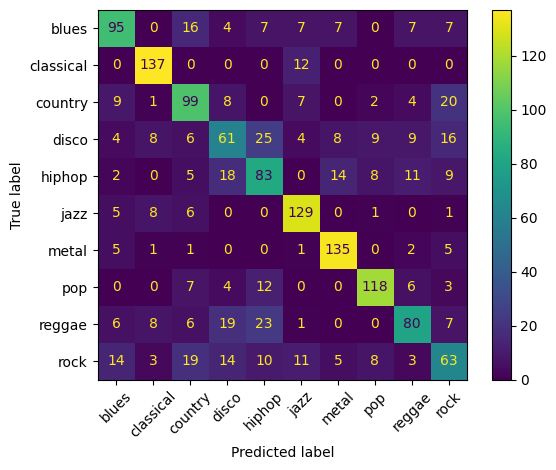

In [7]:
#cell 5 - SVM baseline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

scaler = StandardScaler().fit(X_train) #gia tri MFCC => E()=0, sigma=1
le = LabelEncoder().fit(y_train) #ten the loai nhac => thanh cac con so

svm = SVC(kernel="rbf", C=10, probability=True)  # probability=True lay confidence
svm.fit(scaler.transform(X_train), le.transform(y_train))

pred = svm.predict(scaler.transform(X_test))
print(classification_report(le.transform(y_test), pred, target_names=le.classes_))

ConfusionMatrixDisplay(confusion_matrix(le.transform(y_test), pred),
                       display_labels=le.classes_).plot(xticks_rotation=45)
plt.show()


In [8]:
#cell 5.1 - Majority Voting ()
from collections import Counter

#
song_pred, song_true = [], []
for s in np.unique(s_test):
    m = s_test == s
    song_pred.append(Counter(pred[m]).most_common(1)[0][0])
    song_true.append(le.transform(y_test[m])[0])

print("Số bài test:", len(song_true))
print("Accuracy theo bài:", np.mean(np.array(song_pred) == np.array(song_true)))


Số bài test: 150
Accuracy theo bài: 0.7533333333333333


In [9]:
#cell 6 - K-Means
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

X_all = scaler.transform(X_train)
km = KMeans(n_clusters=10, n_init=10, random_state=42).fit(X_all)

print("Silhouette:", silhouette_score(X_all, km.labels_))
# ARI so sánh cum voi nhan the loai
print("ARI:", adjusted_rand_score(le.transform(y_train), km.labels_))

Silhouette: 0.08567465
ARI: 0.14947638278458675


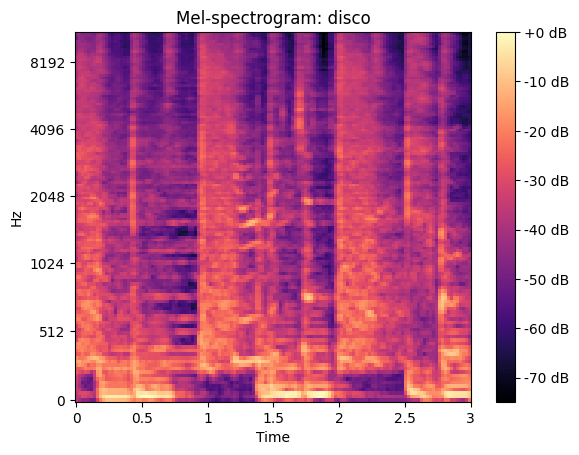

In [10]:
#cell 7 - hien thi mel-spectrogram
import librosa.display

sig, _ = librosa.load(test_f[0], sr=SR, mono=True, duration=3)
mel = librosa.power_to_db(librosa.feature.melspectrogram(y=sig, sr=SR, n_mels=128), ref=np.max)
librosa.display.specshow(mel, sr=SR, x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB"); plt.title(f"Mel-spectrogram: {test_y[0]}")
plt.show()

In [11]:
#cell 8 - tao mel-spectrogram
import os
import numpy as np
import librosa

SR = 22050
SEG = 3 * SR   # số mẫu của 1 đoạn 3 giây

def extract_mel(file_list, label_list):
    M, y, song = [], [], []
    for f, lab in zip(file_list, label_list):
        sig, _ = librosa.load(f, sr=SR, mono=True)
        # Cắt đoạn giống ô 4 để thứ tự đoạn khớp với MFCC
        for i in range(len(sig) // SEG):
            seg = sig[i*SEG:(i+1)*SEG]
            mel = librosa.feature.melspectrogram(
                y=seg, sr=SR, n_fft=2048, hop_length=512, n_mels=128)
            mel_db = librosa.power_to_db(mel, ref=np.max)   # đổi sang dB
            M.append(mel_db.astype(np.float16))              # float16 để nhẹ bộ nhớ
            y.append(lab)
            song.append(f)
    return np.array(M), np.array(y), np.array(song)

M_train, my_train, ms_train = extract_mel(train_f, train_y)
M_val,   my_val,   ms_val   = extract_mel(val_f, val_y)
M_test,  my_test,  ms_test  = extract_mel(test_f, test_y)

print(M_train.shape, M_val.shape, M_test.shape)

# Kiểm tra khớp với MFCC ở ô 4 (cùng số đoạn, cùng thứ tự bài)
assert len(M_train) == len(X_train) and len(M_test) == len(X_test)
assert (ms_train == s_train).all() and (ms_test == s_test).all()

# Mean/std chỉ tính trên tập train, dùng để chuẩn hóa cả 3 tập khi huấn luyện
mel_mean = float(M_train.astype(np.float32).mean())
mel_std  = float(M_train.astype(np.float32).std())
print("mean:", mel_mean, "std:", mel_std)

# Lưu lên Drive (dùng lại save_dir ở phần trước)
np.savez(os.path.join(save_dir, "mel_features.npz"),
         M_train=M_train, y_train=my_train, s_train=ms_train,
         M_val=M_val,     y_val=my_val,     s_val=ms_val,
         M_test=M_test,   y_test=my_test,   s_test=ms_test,
         mean=mel_mean, std=mel_std)
print("Đã lưu")

(6982, 128, 130) (1500, 128, 130) (1499, 128, 130)
mean: -40.57790756225586 std: 15.276609420776367
Đã lưu


In [12]:
#cell 9 - huan luyen chung
import os, json, time
import numpy as np
import torch, torch.nn as nn
import torchvision
from google.colab import drive
from sklearn.preprocessing import LabelEncoder

drive.mount('/content/drive')
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Thiết bị:", device)

# Nạp Mel-spectrogram đã lưu ở ô 8
save_dir = "/content/drive/MyDrive/GTZAN_Project - NHÓM 40"
d = np.load(os.path.join(save_dir, "mel_features.npz"), allow_pickle=True)
M_train, M_val, M_test = d["M_train"], d["M_val"], d["M_test"]
my_train, my_val, my_test = d["y_train"], d["y_val"], d["y_test"]
mel_mean, mel_std = float(d["mean"]), float(d["std"])

le = LabelEncoder().fit(my_train)
NUM_CLASSES = len(le.classes_)

# Đưa toàn bộ dữ liệu lên GPU (giữ float16 cho nhẹ, đổi sang float32 khi dùng)
Xtr, Xva, Xte = [torch.from_numpy(m).to(device) for m in (M_train, M_val, M_test)]
ytr = torch.from_numpy(le.transform(my_train)).long().to(device)
yva = torch.from_numpy(le.transform(my_val)).long().to(device)
yte = torch.from_numpy(le.transform(my_test)).long().to(device)

criterion = nn.CrossEntropyLoss()

def prep(xb):
    # (B,F,T) float16 -> (B,1,F,T) float32, chuẩn hóa bằng mean/std của tập train
    return ((xb.float() - mel_mean) / mel_std).unsqueeze(1)

def spec_augment(x, max_f=20, max_t=20):
    # Che ngẫu nhiên 1 dải tần và 1 dải thời gian cho mỗi mẫu (chỉ dùng cho tập train)
    B, _, F, T = x.shape
    f0 = torch.randint(0, F - max_f, (B, 1, 1, 1), device=x.device)
    fw = torch.randint(0, max_f + 1, (B, 1, 1, 1), device=x.device)
    t0 = torch.randint(0, T - max_t, (B, 1, 1, 1), device=x.device)
    tw = torch.randint(0, max_t + 1, (B, 1, 1, 1), device=x.device)
    fr = torch.arange(F, device=x.device).view(1, 1, F, 1)
    tr = torch.arange(T, device=x.device).view(1, 1, 1, T)
    mask = ((fr >= f0) & (fr < f0 + fw)) | ((tr >= t0) & (tr < t0 + tw))
    return x.masked_fill(mask, 0.0)   # 0 = mức trung bình sau khi chuẩn hóa

def build_model(name):
    # Khởi tạo ngẫu nhiên (weights=None), KHÔNG dùng trọng số pretrained
    if name == "resnet18":
        m = torchvision.models.resnet18(weights=None, num_classes=NUM_CLASSES)
        m.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)  # nhận 1 kênh
    elif name == "efficientnet_b0":
        m = torchvision.models.efficientnet_b0(weights=None, num_classes=NUM_CLASSES)
        m.features[0][0] = nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1, bias=False)
    else:
        raise ValueError(name)
    return m.to(device)

def build_optimizer(params, opt_name, lr, weight_decay):
    if opt_name == "adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if opt_name == "adamw":
        return torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    if opt_name == "sgd":
        return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay, nesterov=True)
    raise ValueError(opt_name)

@torch.no_grad()
def evaluate(model, X, y, batch_size=128):
    model.eval()
    loss_sum, correct, preds = 0.0, 0, []
    for i in range(0, len(X), batch_size):
        xb, yb = prep(X[i:i+batch_size]), y[i:i+batch_size]
        out = model(xb)
        loss_sum += criterion(out, yb).item() * len(yb)
        p = out.argmax(1)
        correct += (p == yb).sum().item()
        preds.append(p)
    return loss_sum / len(X), correct / len(X), torch.cat(preds).cpu().numpy()

def train_model(run_name, model_name, lr, batch_size, opt_name, weight_decay, epochs,
                subset=None, resume=False, augment=True, use_amp=True,
                save_every=5, seed=42, root=None):
    root = root or os.path.join(save_dir, "runs")
    run_dir = os.path.join(root, run_name)
    os.makedirs(run_dir, exist_ok=True)
    torch.manual_seed(seed); np.random.seed(seed)
    amp_on = use_amp and device == "cuda"

    # subset: dùng một phần nhỏ dữ liệu để chạy thử nhanh
    if subset:
        i_tr = torch.randperm(len(Xtr), device=device)[:subset]
        i_va = torch.randperm(len(Xva), device=device)[:max(subset // 2, 64)]
        X_tr, y_tr, X_va, y_va = Xtr[i_tr], ytr[i_tr], Xva[i_va], yva[i_va]
    else:
        X_tr, y_tr, X_va, y_va = Xtr, ytr, Xva, yva

    model = build_model(model_name)
    opt = build_optimizer(model.parameters(), opt_name, lr, weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=amp_on)
    start_epoch, best_val, history = 1, 0.0, []

    # Chỉ tiếp tục từ checkpoint của CHÍNH lần chạy này khi bị ngắt giữa chừng (resume=True)
    last_path = os.path.join(run_dir, "last.pt")
    if resume and os.path.exists(last_path):
        ck = torch.load(last_path, map_location=device)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"])
        start_epoch, best_val, history = ck["epoch"] + 1, ck["best_val"], ck["history"]
        print(f"Tiếp tục từ epoch {start_epoch}")

    for epoch in range(start_epoch, epochs + 1):
        t0 = time.time()
        model.train()
        perm = torch.randperm(len(X_tr), device=device)
        loss_sum, correct = 0.0, 0
        for i in range(0, len(X_tr), batch_size):
            b = perm[i:i+batch_size]
            if len(b) < 2:      # BatchNorm cần ít nhất 2 mẫu
                continue
            xb, yb = prep(X_tr[b]), y_tr[b]
            if augment:
                xb = spec_augment(xb)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", enabled=amp_on):
                out = model(xb)
                loss = criterion(out, yb)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            loss_sum += loss.item() * len(b)
            correct += (out.argmax(1) == yb).sum().item()
        sched.step()

        tr_loss, tr_acc = loss_sum / len(X_tr), correct / len(X_tr)
        va_loss, va_acc, _ = evaluate(model, X_va, y_va)
        history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc,
                            val_loss=va_loss, val_acc=va_acc,
                            lr=opt.param_groups[0]["lr"], sec=time.time() - t0))
        print(f"Epoch {epoch:3d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | {time.time() - t0:.1f}s")

        # Checkpoint: bản tốt nhất (theo val acc) và bản mới nhất để chạy tiếp khi Colab ngắt
        if va_acc > best_val:
            best_val = va_acc
            torch.save(model.state_dict(), os.path.join(run_dir, "best.pt"))
        if epoch % save_every == 0 or epoch == epochs:
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                            epoch=epoch, best_val=best_val, history=history), last_path)
        with open(os.path.join(run_dir, "history.json"), "w") as f:
            json.dump(history, f)
    return history

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thiết bị: cuda


In [14]:
#cell 10 - smoke test
for name in ["resnet18", "efficientnet_b0"]:
    print(f"\n--- Chạy thử {name} ---")
    train_model(f"smoke_{name}", name, lr=1e-3, batch_size=32, opt_name="adamw",
                weight_decay=1e-4, epochs=2, subset=512, save_every=1,
                root="/content/smoke_runs")

# Thử checkpoint: tăng lên 3 epoch với resume=True, phải in "Tiếp tục từ epoch 3"
print("\n--- Thử chạy tiếp từ checkpoint ---")
train_model("smoke_resnet18", "resnet18", lr=1e-3, batch_size=32, opt_name="adamw",
            weight_decay=1e-4, epochs=3, subset=512, save_every=1,
            resume=True, root="/content/smoke_runs")


--- Chạy thử resnet18 ---
Epoch   1/2 | train loss 2.0033 acc 0.2871 | val loss 6.7329 acc 0.1875 | 4.7s
Epoch   2/2 | train loss 1.2655 acc 0.5371 | val loss 1.7871 acc 0.4062 | 0.5s

--- Chạy thử efficientnet_b0 ---
Epoch   1/2 | train loss 3.8698 acc 0.1074 | val loss 2.3695 acc 0.1094 | 3.6s
Epoch   2/2 | train loss 3.0788 acc 0.1660 | val loss 2.3926 acc 0.1094 | 0.9s

--- Thử chạy tiếp từ checkpoint ---
Tiếp tục từ epoch 3
Epoch   3/3 | train loss 0.9287 acc 0.6621 | val loss 1.1950 acc 0.5781 | 0.5s


[{'epoch': 1,
  'train_loss': 2.0033157765865326,
  'train_acc': 0.287109375,
  'val_loss': 6.732864856719971,
  'val_acc': 0.1875,
  'lr': 0.0005,
  'sec': 4.659992456436157},
 {'epoch': 2,
  'train_loss': 1.2654839754104614,
  'train_acc': 0.537109375,
  'val_loss': 1.787144660949707,
  'val_acc': 0.40625,
  'lr': 0.0,
  'sec': 0.4866335391998291},
 {'epoch': 3,
  'train_loss': 0.928714320063591,
  'train_acc': 0.662109375,
  'val_loss': 1.1949729919433594,
  'val_acc': 0.578125,
  'lr': 0.0004999999999999999,
  'sec': 0.4702298641204834}]


===== A_adam_lr1e-3_bs32 =====
Epoch   1/50 | train loss 1.3131 acc 0.5302 | val loss 1.9283 acc 0.4987 | 5.7s
Epoch   2/50 | train loss 0.9311 acc 0.6680 | val loss 1.0291 acc 0.6273 | 5.6s
Epoch   3/50 | train loss 0.7413 acc 0.7449 | val loss 1.3351 acc 0.5833 | 5.6s
Epoch   4/50 | train loss 0.6393 acc 0.7779 | val loss 1.4284 acc 0.6040 | 5.8s
Epoch   5/50 | train loss 0.5227 acc 0.8170 | val loss 1.2069 acc 0.6713 | 5.8s
Epoch   6/50 | train loss 0.4705 acc 0.8343 | val loss 0.8474 acc 0.7333 | 5.8s
Epoch   7/50 | train loss 0.3818 acc 0.8750 | val loss 0.9036 acc 0.7393 | 6.2s
Epoch   8/50 | train loss 0.3156 acc 0.8847 | val loss 1.1293 acc 0.7093 | 6.0s
Epoch   9/50 | train loss 0.3186 acc 0.8869 | val loss 0.7977 acc 0.7627 | 6.2s
Epoch  10/50 | train loss 0.2376 acc 0.9159 | val loss 1.1079 acc 0.7260 | 6.1s
Epoch  11/50 | train loss 0.2088 acc 0.9254 | val loss 1.5112 acc 0.6827 | 6.0s
Epoch  12/50 | train loss 0.2126 acc 0.9222 | val loss 1.0009 acc 0.7347 | 6.6s
Epoch  1

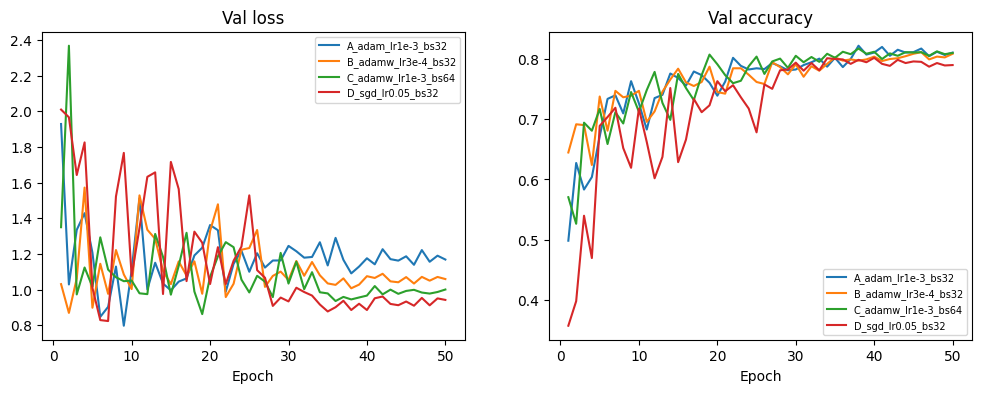

Bộ siêu tham số đề xuất: A_adam_lr1e-3_bs32 {'opt_name': 'adam', 'lr': 0.001, 'batch_size': 32, 'weight_decay': 0.0}


In [17]:
#cell 11 - 50 epoch, checkpoint
import matplotlib.pyplot as plt

SEARCH_MODEL = "resnet18"    # mô hình dùng để dò siêu tham số
SEARCH_EPOCHS = 50

configs = {
    "A_adam_lr1e-3_bs32":  dict(opt_name="adam",  lr=1e-3, batch_size=32, weight_decay=0.0),
    "B_adamw_lr3e-4_bs32": dict(opt_name="adamw", lr=3e-4, batch_size=32, weight_decay=1e-2),
    "C_adamw_lr1e-3_bs64": dict(opt_name="adamw", lr=1e-3, batch_size=64, weight_decay=1e-2),
    "D_sgd_lr0.05_bs32":   dict(opt_name="sgd",   lr=0.05, batch_size=32, weight_decay=5e-4),
}

results = {}
for cname, cfg in configs.items():
    print(f"\n===== {cname} =====")
    # resume=True: nếu Colab ngắt, chạy lại ô này sẽ tiếp tục đúng cấu hình đang dở
    results[cname] = train_model(f"search_{SEARCH_MODEL}_{cname}", SEARCH_MODEL,
                                 epochs=SEARCH_EPOCHS, resume=True, **cfg)

# Bảng tổng hợp
print(f"\n{'Cấu hình':24s}{'best val acc':>13s}{'ở epoch':>9s}{'train acc cuối':>16s}{'val acc cuối':>14s}")
for cname, hist in results.items():
    best = max(hist, key=lambda h: h["val_acc"])
    print(f"{cname:24s}{best['val_acc']:13.4f}{best['epoch']:9d}"
          f"{hist[-1]['train_acc']:16.4f}{hist[-1]['val_acc']:14.4f}")

# Đường cong val của các cấu hình (dùng cho báo cáo)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for cname, hist in results.items():
    ax[0].plot([h["epoch"] for h in hist], [h["val_loss"] for h in hist], label=cname)
    ax[1].plot([h["epoch"] for h in hist], [h["val_acc"] for h in hist], label=cname)
ax[0].set_title("Val loss"); ax[1].set_title("Val accuracy")
for a in ax:
    a.set_xlabel("Epoch"); a.legend(fontsize=7)
plt.show()

best_name = max(results, key=lambda c: max(h["val_acc"] for h in results[c]))
print("Bộ siêu tham số đề xuất:", best_name, configs[best_name])